# T0 — Preparação do ambientes

**Objetivo:** deixar o Codespace pronto, com o servidor do MLflow no ar e os dados da v1 baixados.

Checklist antes de rodar este notebook:
1. Criou o seu repositório a partir do template (**Use this template → Create a new repository**).
2. Abriu o Codespace (**Code → Codespaces → Create codespace on main**) e esperou a instalação terminar.
3. Abriu um terminal (**Ctrl + `**) e subiu o MLflow. **Deixe esse terminal aberto o dia todo**:
   ```bash
   bash scripts/start_mlflow.sh
   ```
4. Na aba **PORTAS** (PORTS), abriu a porta **5000 (MLflow UI)** no navegador.

In [1]:
import os, sys
from pathlib import Path

# Trabalha a partir da raiz do repositório (a pasta que contém o params.yaml)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "params.yaml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

## 1. Versões das ferramentas

In [2]:
import mlflow, dvc, sklearn, pandas as pd
pd.set_option("display.width", 160)

print("Python      ", sys.version.split()[0])
print("MLflow      ", mlflow.__version__)
print("DVC         ", dvc.__version__)
print("scikit-learn", sklearn.__version__)
print("pandas      ", pd.__version__)

Python      

3.13.16

MLflow      

3.17.0

DVC         

3.67.1

scikit-learn

1.9.1

pandas      

3.0.6

## 2. O servidor do MLflow está no ar?

In [3]:
import urllib.request
from bike import tracking_uri

uri = tracking_uri()
try:
    urllib.request.urlopen(f"{uri}/health", timeout=5)
    print(f"✅ Servidor MLflow respondendo em {uri}")
except Exception:
    print(f"❌ Nada em {uri}. Abra um terminal e rode: bash scripts/start_mlflow.sh")

✅ Servidor MLflow respondendo em http://127.0.0.1:5000

## 3. Baixar os dados (versão 1 = ano de 2011)

O script `src/get_data.py` baixa o *Bike Sharing Dataset* (UCI) e grava apenas os dados
**disponíveis até** uma data. Assim simulamos dados novos chegando ao longo do tempo.

In [4]:
%%bash
python src/get_data.py --until 2011-12-31

data/raw/bike.csv: 8,645 linhas | 2011-01-01 a 2011-12-31


## 4. Conhecendo os dados

| Coluna | Significado |
|---|---|
| `dteday`, `hr` | data e hora (0–23) |
| `season` | estação (1 inverno, 2 primavera, 3 verão, 4 outono) |
| `yr` | ano (0 = 2011, 1 = 2012) |
| `mnth`, `weekday` | mês (1–12) e dia da semana (0 = domingo) |
| `holiday`, `workingday` | feriado / dia útil (0 ou 1) |
| `weathersit` | clima (1 limpo … 4 tempestade) |
| `temp`, `atemp`, `hum`, `windspeed` | temperatura, sensação térmica, umidade e vento (normalizados 0–1) |
| `casual`, `registered` | aluguéis de usuários avulsos / cadastrados |
| **`cnt`** | **alvo: total de aluguéis na hora** (`casual + registered`) |

> ⚠️ `casual` e `registered` **não** entram no modelo: somadas, elas são o próprio alvo (vazamento de dados).

(8645, 17)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


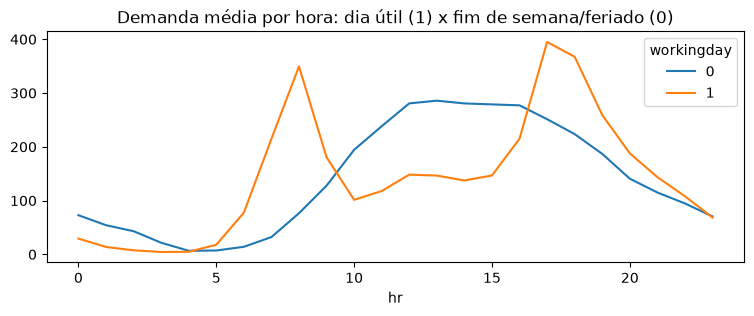

In [5]:
from IPython.display import display
from bike import FEATURES, TARGET, load_raw

df = load_raw()
print(df.shape)
display(df.head())

ax = df.groupby(["workingday", "hr"])[TARGET].mean().unstack(0).plot(
    figsize=(9, 3), title="Demanda média por hora: dia útil (1) x fim de semana/feriado (0)")